# Why did SMOTENC change accuracy more than F1 or PR-AUC?

This post-call UCI Bank Marketing experiment uses `duration`, a stratified 60/20/20 split (seed 42), and 5,000 synthetic subscribers. Preprocessing and sampling use training rows only, including stacking folds. Validation selects methods and cutoffs; test results are descriptive. Run from anywhere inside the repository with the project dependencies and UCI API access.

In [26]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from imblearn.over_sampling import ADASYN, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    if root == root.parent:
        raise RuntimeError("Run from inside the project repository")
    root = root.parent
sys.path.insert(0, str(root / "eda/uci_banking"))
from scripts.uci_preprocessing import load_and_preprocess_uci
from scripts.uci_preprocessing_smotenc import make_smotenc_model_pipeline

SEED = 42
N_SYNTHETIC = 5000
METRICS = ["accuracy", "f1", "precision", "recall", "pr_auc", "brier"]
pd.options.display.float_format = "{:.4f}".format
data = load_and_preprocess_uci(seed=SEED, include_duration=True)
X_train, X_val, X_test = data.X_train, data.X_val, data.X_test
y_train, y_val, y_test = data.y_train, data.y_val, data.y_test
preprocessor = data.preprocessor
counts = y_train.value_counts()
smotenc_ratio = (int(counts.loc[1]) + N_SYNTHETIC) / int(counts.loc[0])
print("Split sizes:", {"train": len(y_train), "validation": len(y_val), "test": len(y_test)})
print("Training prevalence:", round(y_train.mean(), 4), "SMOTENC target minority/majority ratio:", round(smotenc_ratio, 4))
assert "duration" in X_train.columns
assert X_train.index.is_unique and not X_train.index.intersection(X_val.index).size
assert not X_train.index.intersection(X_test.index).size


Split sizes: {'train': 27126, 'validation': 9042, 'test': 9043}
Training prevalence: 0.117 SMOTENC target minority/majority ratio: 0.3412


In [27]:
def pr_auc(y, p):
    precision, recall, _ = precision_recall_curve(y, p)
    return auc(recall, precision)  # Matches the two source notebooks (trapezoidal PR-AUC).


def score(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y, pred),
        "f1": f1_score(y, pred, zero_division=0),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "pr_auc": pr_auc(y, p),
        "brier": brier_score_loss(y, p),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "predicted_yes": int(pred.sum()),
        "mean_probability": float(np.mean(p)),
    }


def make_models():
    models = {
        "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Decision tree": DecisionTreeClassifier(random_state=SEED),
        "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=SEED),
        "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
        "XGBoost": xgb.XGBClassifier(n_estimators=150, n_jobs=2, random_state=SEED),
        "LightGBM": lgb.LGBMClassifier(n_estimators=150, verbosity=-1, n_jobs=2, random_state=SEED),
        "CatBoost": CatBoostClassifier(iterations=200, thread_count=2, verbose=0,
                                        random_seed=SEED, allow_writing_files=False),
    }
    return models


def stacking(models, smotenc=False):
    names = [("logistic", "Logistic regression"), ("forest", "Random forest"),
             ("lightgbm", "LightGBM")]
    estimators = [(short, make_smotenc_model_pipeline(models[long], preprocessor,
                   X_train, smotenc_ratio, SEED) if smotenc else
                   make_pipeline(clone(preprocessor), clone(models[long])))
                  for short, long in names]
    return StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
        stack_method="predict_proba", cv=3, n_jobs=1,
    )


models = make_models()
models["Stacking ensemble"] = stacking(models)


## Paired eight-model comparison

Each model is fitted on the same training split with and without SMOTENC. Tables show validation and test metrics; differences are SMOTENC minus baseline. Lower Brier is better.

In [28]:
rows = []
probabilities = {}
trained_stacks = {}
for name, model in models.items():
    for method in ("Baseline", "SMOTENC"):
        if method == "Baseline":
            pipeline = clone(model) if name == "Stacking ensemble" else make_pipeline(
                clone(preprocessor), clone(model))
        elif name == "Stacking ensemble":
            pipeline = stacking(make_models(), smotenc=True)
        else:
            pipeline = make_smotenc_model_pipeline(model, preprocessor, X_train,
                                                   smotenc_ratio, SEED)
        pipeline.fit(X_train, y_train)
        if name == "Stacking ensemble":
            trained_stacks[method] = pipeline
        for split, X, y in (("validation", X_val, y_val), ("test", X_test, y_test)):
            p = pipeline.predict_proba(X)[:, 1]
            probabilities[(name, method, split)] = p
            rows.append({"model": name, "method": method, "split": split, **score(y, p)})
        print("Finished", name, method, flush=True)

results = pd.DataFrame(rows).set_index(["model", "method", "split"]).sort_index()
for split in ("validation", "test"):
    base = results.xs(("Baseline", split), level=("method", "split"))
    smote = results.xs(("SMOTENC", split), level=("method", "split"))
    delta = smote[METRICS + ["fp", "tp"]] - base[METRICS + ["fp", "tp"]]
    print(f"\n{split.title()}: SMOTENC minus baseline (positive delta is not always better)")
    display(delta.round(4))
    print("Absolute scores (baseline then SMOTENC):")
    display(results.xs(split, level="split")[METRICS + ["tn", "fp", "fn", "tp"]].round(4))

Finished Logistic regression Baseline
Finished Logistic regression SMOTENC
Finished Decision tree Baseline
Finished Decision tree SMOTENC
Finished Random forest Baseline
Finished Random forest SMOTENC
Finished Gradient boosting Baseline
Finished Gradient boosting SMOTENC
Finished XGBoost Baseline
Finished XGBoost SMOTENC
Finished LightGBM Baseline
Finished LightGBM SMOTENC
Finished CatBoost Baseline
Finished CatBoost SMOTENC
Finished Stacking ensemble Baseline
Finished Stacking ensemble SMOTENC

Validation: SMOTENC minus baseline (positive delta is not always better)


,accuracy,f1,precision,recall,pr_auc,brier,fp,tp
model,,,,,,,,
CatBoost,0.0036,0.0524,-0.0070,0.0898,0.0084,0.0002,62,95
Decision tree,-0.0098,-0.0090,-0.0351,0.0198,-0.0088,0.0098,110,21
Gradient boosting,-0.0075,0.0733,-0.1008,0.1805,-0.0241,0.0046,259,191
LightGBM,0.0018,0.0622,-0.0285,0.1238,-0.0130,0.0017,115,131
Logistic regression,-0.0041,0.1169,-0.0886,0.2344,-0.0136,0.0076,285,248
Random forest,-0.0027,0.0776,-0.0699,0.1578,-0.0166,0.0033,191,167
Stacking ensemble,-0.0007,0.0091,-0.0140,0.0208,-0.0108,0.0003,28,22
XGBoost,-0.0039,0.0283,-0.0434,0.0813,-0.0200,0.0029,121,86


Absolute scores (baseline then SMOTENC):


accuracy     f1  precision  recall  pr_auc  \
model               method                                                 
CatBoost            Baseline    0.9081 0.5466     0.6465  0.4735  0.6098   
                    SMOTENC     0.9117 0.5990     0.6395  0.5633  0.6182   
Decision tree       Baseline    0.8775 0.4739     0.4761  0.4716  0.5048   
                    SMOTENC     0.8676 0.4649     0.4411  0.4915  0.4960   
Gradient boosting   Baseline    0.9064 0.5000     0.6672  0.3998  0.5887   
                    SMOTENC     0.8989 0.5733     0.5664  0.5803  0.5647   
LightGBM            Baseline    0.9081 0.5432     0.6491  0.4669  0.6209   
                    SMOTENC     0.9099 0.6053     0.6207  0.5907  0.6078   
Logistic regression Baseline    0.9019 0.4562     0.6492  0.3516  0.5500   
                    SMOTENC     0.8978 0.5730     0.5606  0.5860  0.5364   
Random forest       Baseline    0.9050 0.4902     0.6587  0.3904  0.6096   
                    SMOTENC     0.9023 0.5678     0.5888  0.5482  0.5930   
Stacking ensemble   Baseline    0.9094 0.5447     0.6613  0.4631  0.6291   
                    SMOTENC     0.9088 0.5538     0.6473  0.4839  0.6184   
XGBoost             Baseline    0.9062 0.5465     0.6293  0.4830  0.6040   
                    SMOTENC     0.9023 0.5749     0.5859  0.5643  0.5840   

                              brier    tn   fp   fn   tp  
model               method                                
CatBoost            Baseline 0.0630  7710  274  557  501  
                    SMOTENC  0.0632  7648  336  462  596  
Decision tree       Baseline 0.1225  7435  549  559  499  
                    SMOTENC  0.1324  7325  659  538  520  
Gradient boosting   Baseline 0.0664  7773  211  635  423  
                    SMOTENC  0.0711  7514  470  444  614  
LightGBM            Baseline 0.0625  7717  267  564  494  
                    SMOTENC  0.0642  7602  382  433  625  
Logistic regression Baseline 0.0714  7783  201  686  372  
                    SMOTENC  0.0790  7498  486  438  620  
Random forest       Baseline 0.0642  7770  214  645  413  
                    SMOTENC  0.0675  7579  405  478  580  
Stacking ensemble   Baseline 0.0646  7733  251  568  490  
                    SMOTENC  0.0649  7705  279  546  512  
XGBoost             Baseline 0.0654  7683  301  547  511  
                    SMOTENC  0.0684  7562  422  461  597


Test: SMOTENC minus baseline (positive delta is not always better)


,accuracy,f1,precision,recall,pr_auc,brier,fp,tp
model,,,,,,,,
CatBoost,-0.0013,0.0329,-0.0391,0.0775,-0.0021,0.0005,94,82
Decision tree,-0.0015,0.0246,-0.0021,0.0567,0.0240,0.0015,74,60
Gradient boosting,-0.0033,0.0830,-0.0848,0.1824,-0.0075,0.0034,223,193
LightGBM,-0.0035,0.0330,-0.0514,0.0926,-0.0009,0.0013,130,98
Logistic regression,-0.0074,0.1065,-0.1163,0.2268,-0.0168,0.0073,307,240
Random forest,-0.0065,0.0519,-0.0914,0.1352,-0.0256,0.0033,202,143
Stacking ensemble,-0.0033,-0.0027,-0.0302,0.0123,-0.0142,0.0012,43,13
XGBoost,-0.0040,0.0189,-0.0439,0.0633,-0.0023,0.0015,103,67


Absolute scores (baseline then SMOTENC):


accuracy     f1  precision  recall  pr_auc  \
model               method                                                 
CatBoost            Baseline    0.9119 0.5604     0.6728  0.4802  0.6438   
                    SMOTENC     0.9105 0.5933     0.6337  0.5577  0.6417   
Decision tree       Baseline    0.8749 0.4757     0.4668  0.4849  0.5060   
                    SMOTENC     0.8734 0.5002     0.4647  0.5416  0.5300   
Gradient boosting   Baseline    0.9079 0.5074     0.6777  0.4055  0.6174   
                    SMOTENC     0.9046 0.5904     0.5929  0.5879  0.6100   
LightGBM            Baseline    0.9104 0.5603     0.6582  0.4877  0.6362   
                    SMOTENC     0.9069 0.5932     0.6067  0.5803  0.6352   
Logistic regression Baseline    0.9038 0.4583     0.6715  0.3478  0.5599   
                    SMOTENC     0.8964 0.5648     0.5553  0.5747  0.5431   
Random forest       Baseline    0.9090 0.5196     0.6794  0.4206  0.6335   
                    SMOTENC     0.9025 0.5714     0.5880  0.5558  0.6080   
Stacking ensemble   Baseline    0.9109 0.5547     0.6676  0.4745  0.6501   
                    SMOTENC     0.9076 0.5520     0.6374  0.4868  0.6360   
XGBoost             Baseline    0.9094 0.5618     0.6473  0.4962  0.6113   
                    SMOTENC     0.9055 0.5807     0.6035  0.5595  0.6091   

                              brier    tn   fp   fn   tp  
model               method                                
CatBoost            Baseline 0.0606  7738  247  550  508  
                    SMOTENC  0.0611  7644  341  468  590  
Decision tree       Baseline 0.1251  7399  586  545  513  
                    SMOTENC  0.1266  7325  660  485  573  
Gradient boosting   Baseline 0.0640  7781  204  629  429  
                    SMOTENC  0.0674  7558  427  436  622  
LightGBM            Baseline 0.0608  7717  268  542  516  
                    SMOTENC  0.0620  7587  398  444  614  
Logistic regression Baseline 0.0701  7805  180  690  368  
                    SMOTENC  0.0775  7498  487  450  608  
Random forest       Baseline 0.0623  7775  210  613  445  
                    SMOTENC  0.0656  7573  412  470  588  
Stacking ensemble   Baseline 0.0626  7735  250  556  502  
                    SMOTENC  0.0638  7692  293  543  515  
XGBoost             Baseline 0.0651  7699  286  533  525  
                    SMOTENC  0.0666  7596  389  466  592

## Errors at the 0.5 cutoff

The matrices show `[[TN, FP], [FN, TP]]` with subscriber (`yes`) as positive. PR-AUC uses all cutoffs; the confusion counts use 0.5.

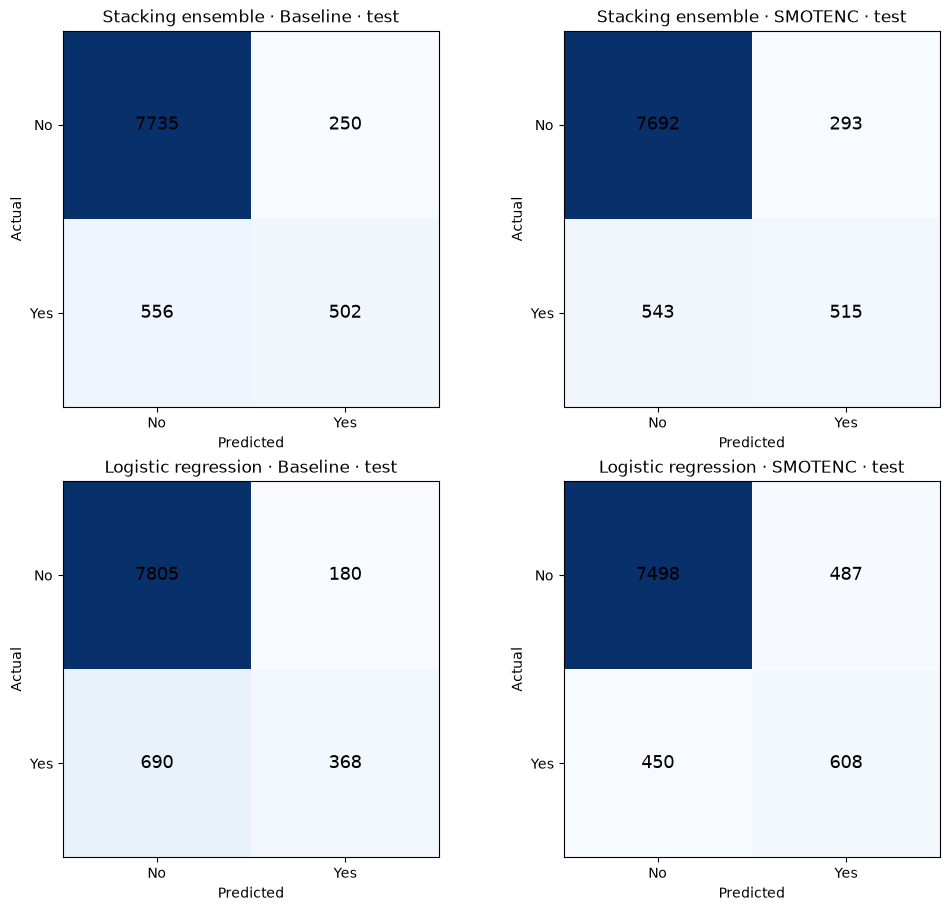

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for row, name in enumerate(("Stacking ensemble", "Logistic regression")):
    for col, method in enumerate(("Baseline", "SMOTENC")):
        p = probabilities[(name, method, "test")]
        matrix = confusion_matrix(y_test, p >= 0.5, labels=[0, 1])
        ax = axes[row, col]
        ax.imshow(matrix, cmap="Blues")
        for (i, j), value in np.ndenumerate(matrix):
            ax.text(j, i, str(value), ha="center", va="center", fontsize=13)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No", "Yes"],
               yticklabels=["No", "Yes"], xlabel="Predicted", ylabel="Actual",
               title=f"{name} · {method} · test")
plt.show()


### Average decision areas: age and call duration

Both panels use the fitted stacking models, the same test dots, and the same age/duration grid. For each grid point, probability is averaged over 30 training profiles with their other features retained. Pale blue means **predict no** (average probability <0.5); pale red means **predict yes** (≥0.5). Dots show actual outcomes, so a dot's own full-feature prediction may differ from its background.

The area table measures only the displayed rectangle. Its area percentages are **not** customer percentages; the last column uses predictions on the full test set.

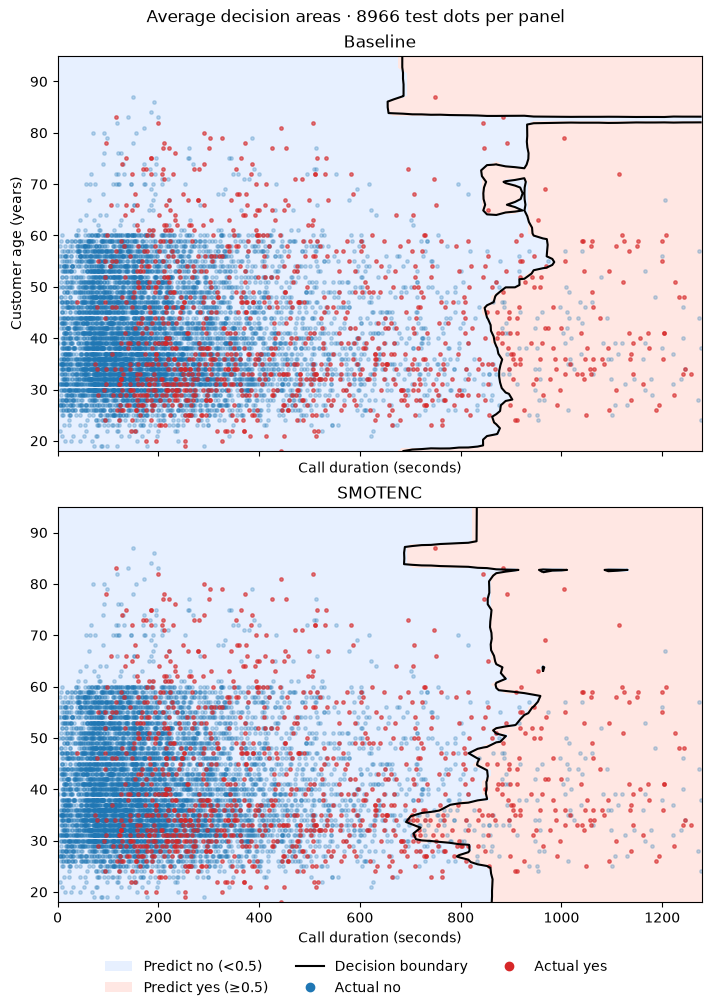

,predict no area (year·second),predict yes area (year·second),predict no area (%),predict yes area (%),test customers predicted yes (%)
model,,,,,
Baseline,66795.2000,31630.0000,67.9000,32.1000,8.3000
SMOTENC,64717.5000,33707.7000,65.8000,34.2000,8.9000


In [45]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

reference = X_train.sample(n=min(100, len(X_train)), random_state=SEED)
max_duration = X_train["duration"].quantile(0.99)
shown = X_test.loc[X_test["duration"] <= max_duration]
actual = y_test.loc[shown.index]
durations = np.linspace(0, max_duration, 70)
ages = np.linspace(X_train["age"].min(), X_train["age"].max(), 70)
duration_grid, age_grid = np.meshgrid(durations, ages)
grid = reference.loc[reference.index.repeat(duration_grid.size)].reset_index(drop=True)
grid["age"] = np.tile(age_grid.ravel(), len(reference))
grid["duration"] = np.tile(duration_grid.ravel(), len(reference))

fig, axes = plt.subplots(2, 1, figsize=(7, 10), sharex=True, sharey=True,
                         layout="constrained")
area_rows = []
area_total = (ages[-1] - ages[0]) * (durations[-1] - durations[0])
for ax, method in zip(axes, ("Baseline", "SMOTENC")):
    p = trained_stacks[method].predict_proba(grid)[:, 1].reshape(
        len(reference), *duration_grid.shape).mean(axis=0)
    yes_area = np.trapezoid(np.trapezoid((p >= 0.5).astype(float), durations, axis=1), ages)
    area_rows.append({
        "model": method,
        "predict no area (year·second)": area_total - yes_area,
        "predict yes area (year·second)": yes_area,
        "predict no area (%)": 100 * (area_total - yes_area) / area_total,
        "predict yes area (%)": 100 * yes_area / area_total,
        "test customers predicted yes (%)": 100 * results.loc[
            ("Stacking ensemble", method, "test"), "predicted_yes"] / len(y_test),
    })
    ax.contourf(duration_grid, age_grid, p >= 0.5, levels=[-0.5, 0.5, 1.5],
                colors=["#e7f0ff", "#ffe7e3"])
    if p.min() < 0.5 < p.max():
        ax.contour(duration_grid, age_grid, p, levels=[0.5], colors="black",
                   linewidths=1.5)
    for label, color in ((0, "tab:blue"), (1, "tab:red")):
        points = shown.loc[actual == label]
        ax.scatter(points["duration"], points["age"], s=6, alpha=0.25 if label == 0 else 0.6,
                   color=color)
    ax.set(title=method, xlabel="Call duration (seconds)",
           xlim=(durations.min(), durations.max()),
           ylim=(ages.min(), ages.max()))
axes[0].set_ylabel("Customer age (years)")
fig.legend(handles=[
    Patch(facecolor="#e7f0ff", label="Predict no (<0.5)"),
    Patch(facecolor="#ffe7e3", label="Predict yes (≥0.5)"),
    Line2D([], [], color="black", linewidth=1.5, label="Decision boundary"),
    Line2D([], [], marker="o", linestyle="none", color="tab:blue", label="Actual no"),
    Line2D([], [], marker="o", linestyle="none", color="tab:red", label="Actual yes"),
], loc="outside lower center", ncol=3, frameon=False)
fig.suptitle(f"Average decision areas · {len(shown)} test dots per panel")
plt.show()
display(pd.DataFrame(area_rows).set_index("model").round(1))

#### Why the areas can shift

Within SMOTENC base learners, synthetic subscribers raise training class odds from $n_+/n_-$ to target odds $r$. Under a pure prior shift, subscriber log odds would rise by $\log[r/(n_+/n_-)]$, making more predictions cross 0.5. Synthetic neighbors also change learned patterns, and the stack's final learner uses original labels, so this is a mechanism rather than a complete model of the fitted stack.

In [46]:
from IPython.display import Markdown

n_positive = int(counts.loc[1])
n_negative = int(counts.loc[0])
original_odds = n_positive / n_negative
odds_multiplier = smotenc_ratio / original_odds
base = results.loc[("Stacking ensemble", "Baseline", "test")]
smote = results.loc[("Stacking ensemble", "SMOTENC", "test")]
tp_change = int(smote["tp"] - base["tp"])
fp_change = int(smote["fp"] - base["fp"])
accuracy_change = (tp_change - fp_change) / len(y_test)
display(Markdown(
    f"**Training odds:** {original_odds:.4f} → {smotenc_ratio:.4f} "
    f"(×{odds_multiplier:.3f}). Under a pure prior shift, a sampled-model "
    f"0.5 cutoff corresponds to an original-model probability of "
    f"{1 / (1 + odds_multiplier):.3f}; this is not a calibrated stack cutoff.\n\n"
    f"**Stacking test ({len(y_test):,} customers):** ΔTP {tp_change:+d}, "
    f"ΔFP {fp_change:+d}, Δaccuracy = "
    f"`({tp_change} - {fp_change}) / {len(y_test)} = {accuracy_change:+.4f}`. "
    f"Brier {base['brier']:.4f} → {smote['brier']:.4f}; "
    f"PR-AUC {base['pr_auc']:.4f} → {smote['pr_auc']:.4f}."
))

**Training odds:** 0.1325 → 0.3412 (×2.576). Under a pure prior shift, a sampled-model 0.5 cutoff corresponds to an original-model probability of 0.280; this is not a calibrated stack cutoff.

**Stacking test (9,043 customers):** ΔTP +13, ΔFP +43, Δaccuracy = `(13 - 43) / 9043 = -0.0033`. Brier 0.0626 → 0.0638; PR-AUC 0.6501 → 0.6360.

## Probability calibration

Brier score is mean squared probability error (lower is better). Reliability curves compare predicted and observed subscriber rates.

brier  mean_probability  \
model               method   split                                 
CatBoost            Baseline test       0.0606            0.1128   
                             validation 0.0630            0.1154   
                    SMOTENC  test       0.0611            0.1285   
                             validation 0.0632            0.1300   
Decision tree       Baseline test       0.1251            0.1215   
                             validation 0.1225            0.1159   
                    SMOTENC  test       0.1266            0.1363   
                             validation 0.1324            0.1304   
Gradient boosting   Baseline test       0.0640            0.1152   
                             validation 0.0664            0.1165   
                    SMOTENC  test       0.0674            0.1619   
                             validation 0.0711            0.1636   
LightGBM            Baseline test       0.0608            0.1127   
                             validation 0.0625            0.1136   
                    SMOTENC  test       0.0620            0.1321   
                             validation 0.0642            0.1344   
Logistic regression Baseline test       0.0701            0.1149   
                             validation 0.0714            0.1170   
                    SMOTENC  test       0.0775            0.1841   
                             validation 0.0790            0.1861   
Random forest       Baseline test       0.0623            0.1153   
                             validation 0.0642            0.1165   
                    SMOTENC  test       0.0656            0.1477   
                             validation 0.0675            0.1489   
Stacking ensemble   Baseline test       0.0626            0.1172   
                             validation 0.0646            0.1175   
                    SMOTENC  test       0.0638            0.1175   
                             validation 0.0649            0.1186   
XGBoost             Baseline test       0.0651            0.1103   
                             validation 0.0654            0.1108   
                    SMOTENC  test       0.0666            0.1264   
                             validation 0.0684            0.1283   

                                         actual_prevalence  
model               method   split                          
CatBoost            Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Decision tree       Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Gradient boosting   Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
LightGBM            Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Logistic regression Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Random forest       Baseline test                   0.1170  
                             validation             0.1170  
                    SMOTENC  test                   0.1170  
                             validation             0.1170  
Stacking ensemble   Baseline test                   0.1170  
                             validation             0.1170  
                    

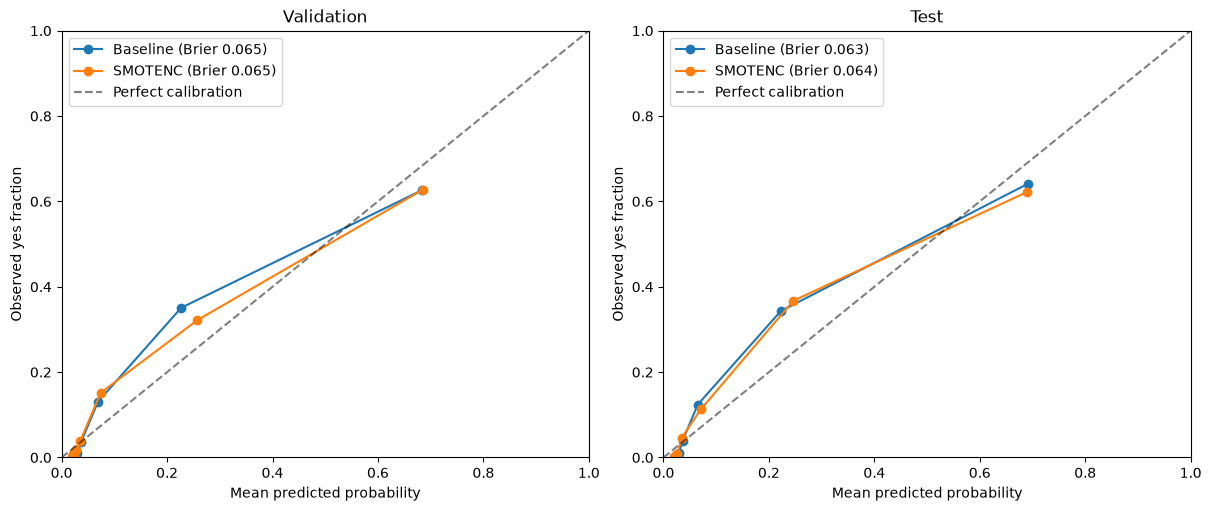

In [47]:
calibration = results[["brier", "mean_probability"]].copy()
calibration["actual_prevalence"] = [float(y_val.mean() if idx[2] == "validation" else y_test.mean())
                                    for idx in calibration.index]
display(calibration.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, split, y in zip(axes, ("validation", "test"), (y_val, y_test)):
    for method in ("Baseline", "SMOTENC"):
        p = probabilities[("Stacking ensemble", method, split)]
        observed, predicted = calibration_curve(y, p, n_bins=10, strategy="quantile")
        ax.plot(predicted, observed, marker="o", label=f"{method} (Brier {brier_score_loss(y, p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect calibration")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed yes fraction", title=split.title(),
           xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.show()


## Other balancing choices: logistic regression

All methods use the same split. SMOTENC adds 5,000 subscribers; ADASYN, BorderlineSMOTE, and undersampling target the same minority/majority ratio. ADASYN and BorderlineSMOTE operate after one-hot encoding, so their synthetic categorical coordinates are exploratory model inputs. The baseline cutoff is tuned for F1 on validation only.

In [48]:
lr = LogisticRegression(max_iter=1000, random_state=SEED)
alternatives = {
    "Baseline": make_pipeline(clone(preprocessor), clone(lr)),
    "SMOTENC": make_smotenc_model_pipeline(lr, preprocessor, X_train, smotenc_ratio, SEED),
    "Class weights": make_pipeline(clone(preprocessor), LogisticRegression(
        max_iter=1000, random_state=SEED, class_weight="balanced")),
    "ADASYN": make_imb_pipeline(clone(preprocessor), ADASYN(
        sampling_strategy=smotenc_ratio, random_state=SEED), clone(lr)),
    "BorderlineSMOTE": make_imb_pipeline(clone(preprocessor), BorderlineSMOTE(
        sampling_strategy=smotenc_ratio, random_state=SEED), clone(lr)),
    "Undersampling": make_imb_pipeline(RandomUnderSampler(
        sampling_strategy=smotenc_ratio, random_state=SEED), clone(preprocessor), clone(lr)),
}
alternative_rows = []
alternative_probabilities = {}
for method, pipeline in alternatives.items():
    pipeline.fit(X_train, y_train)
    for split, X, y in (("validation", X_val, y_val), ("test", X_test, y_test)):
        p = pipeline.predict_proba(X)[:, 1]
        alternative_probabilities[(method, split)] = p
        alternative_rows.append({"method": method, "split": split, "cutoff": 0.5, **score(y, p)})
    print("Finished", method, flush=True)

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_val, alternative_probabilities[("Baseline", "validation")])
f1_curve = 2 * precision_curve[:-1] * recall_curve[:-1] / np.maximum(
    precision_curve[:-1] + recall_curve[:-1], 1e-12)
best_cutoff = float(thresholds[np.argmax(f1_curve)])
for split, y in (("validation", y_val), ("test", y_test)):
    p = alternative_probabilities[("Baseline", split)]
    alternative_rows.append({"method": "Tuned cutoff", "split": split,
                             "cutoff": best_cutoff, **score(y, p, best_cutoff)})
alternative_results = pd.DataFrame(alternative_rows).set_index(["method", "split"])
print("Validation-selected F1 cutoff:", round(best_cutoff, 4))
for split in ("validation", "test"):
    print(split.title())
    display(alternative_results.xs(split, level="split")[["cutoff"] + METRICS +
            ["tn", "fp", "fn", "tp"]].round(4))


Finished Baseline
Finished SMOTENC
Finished Class weights
Finished ADASYN
Finished BorderlineSMOTE
Finished Undersampling
Validation-selected F1 cutoff: 0.1691
Validation


,cutoff,accuracy,f1,precision,recall,pr_auc,brier,tn,fp,fn,tp
method,,,,,,,,,,,
Baseline,0.5000,0.9019,0.4562,0.6492,0.3516,0.5500,0.0714,7783,201,686,372
SMOTENC,0.5000,0.8978,0.5730,0.5606,0.5860,0.5364,0.0790,7498,486,438,620
Class weights,0.5000,0.8437,0.5501,0.4148,0.8166,0.5432,0.1206,6765,1219,194,864
ADASYN,0.5000,0.8919,0.5794,0.5320,0.6361,0.5442,0.0828,7392,592,385,673
BorderlineSMOTE,0.5000,0.8950,0.5788,0.5456,0.6163,0.5441,0.0804,7441,543,406,652
Undersampling,0.5000,0.8975,0.5702,0.5596,0.5813,0.5467,0.0784,7500,484,443,615
Tuned cutoff,0.1691,0.8759,0.5801,0.4802,0.7325,0.5500,0.0714,7145,839,283,775


Test


,cutoff,accuracy,f1,precision,recall,pr_auc,brier,tn,fp,fn,tp
method,,,,,,,,,,,
Baseline,0.5000,0.9038,0.4583,0.6715,0.3478,0.5599,0.0701,7805,180,690,368
SMOTENC,0.5000,0.8964,0.5648,0.5553,0.5747,0.5431,0.0775,7498,487,450,608
Class weights,0.5000,0.8498,0.5594,0.4259,0.8147,0.5485,0.1176,6823,1162,196,862
ADASYN,0.5000,0.8937,0.5852,0.5385,0.6408,0.5490,0.0808,7404,581,380,678
BorderlineSMOTE,0.5000,0.8955,0.5820,0.5470,0.6219,0.5487,0.0785,7440,545,400,658
Undersampling,0.5000,0.8991,0.5754,0.5670,0.5841,0.5576,0.0760,7513,472,440,618
Tuned cutoff,0.1691,0.8770,0.5785,0.4829,0.7212,0.5599,0.0701,7168,817,295,763


## Benchmark for a future GAN

Select the strongest PR-AUC model and the strongest 0.5-cutoff F1 model on validation; also tune the ranking winner's cutoff on validation. Compare a GAN with the strongest relevant non-GAN method using the same downstream model, then evaluate once on a **fresh holdout**. The current test results have already been inspected.

In [49]:
validation_all = results.xs("validation", level="split")
best_rank = validation_all["pr_auc"].idxmax()
val_alt = alternative_results.xs("validation", level="split").drop(index="Tuned cutoff")
best_05 = validation_all["f1"].idxmax()
if val_alt["f1"].max() > validation_all["f1"].max():
    best_05 = ("Logistic regression", val_alt["f1"].idxmax())
rank_val_p = probabilities[(*best_rank, "validation")]
rank_test_p = probabilities[(*best_rank, "test")]
rank_precision, rank_recall, rank_thresholds = precision_recall_curve(y_val, rank_val_p)
rank_f1 = 2 * rank_precision[:-1] * rank_recall[:-1] / np.maximum(
    rank_precision[:-1] + rank_recall[:-1], 1e-12)
rank_cutoff = float(rank_thresholds[np.argmax(rank_f1)])
rank_tuned = pd.DataFrame([
    {"split": "validation", "cutoff": rank_cutoff, **score(y_val, rank_val_p, rank_cutoff)},
    {"split": "test", "cutoff": rank_cutoff, **score(y_test, rank_test_p, rank_cutoff)},
]).set_index("split")
print("Ranking benchmark selected on validation:", best_rank)
display(results.loc[(*best_rank, slice(None)), METRICS + ["fp", "tp"]].round(4))
print("Best 0.5-cutoff F1 on validation:", best_05)
if best_05[0] == "Logistic regression" and best_05[1] not in ("Baseline", "SMOTENC"):
    display(alternative_results.loc[(best_05[1], slice(None)),
                                    ["cutoff"] + METRICS + ["fp", "tp"]].round(4))
else:
    display(results.loc[(*best_05, slice(None)), METRICS + ["fp", "tp"]].round(4))
print("Ranking winner with validation-tuned F1 cutoff:")
display(rank_tuned[["cutoff"] + METRICS + ["fp", "tp"]].round(4))


Ranking benchmark selected on validation: ('Stacking ensemble', 'Baseline')


accuracy     f1  precision  recall  \
model             method   split                                            
Stacking ensemble Baseline test          0.9109 0.5547     0.6676  0.4745   
                           validation    0.9094 0.5447     0.6613  0.4631   

                                       pr_auc  brier   fp   tp  
model             method   split                                
Stacking ensemble Baseline test        0.6501 0.0626  250  502  
                           validation  0.6291 0.0646  251  490

Best 0.5-cutoff F1 on validation: ('LightGBM', 'SMOTENC')


accuracy     f1  precision  recall  pr_auc  \
model    method  split                                                    
LightGBM SMOTENC test          0.9069 0.5932     0.6067  0.5803  0.6352   
                 validation    0.9099 0.6053     0.6207  0.5907  0.6078   

                             brier   fp   tp  
model    method  split                        
LightGBM SMOTENC test       0.0620  398  614  
                 validation 0.0642  382  625

Ranking winner with validation-tuned F1 cutoff:


,cutoff,accuracy,f1,precision,recall,pr_auc,brier,fp,tp
split,,,,,,,,,
validation,0.1706,0.8964,0.6350,0.5401,0.7703,0.6291,0.0646,694,815
test,0.1706,0.9003,0.6421,0.5534,0.7647,0.6501,0.0626,653,809
